# <font color="#0b486b">FIT3181 | FIT5215: Deep Learning (2026)</font>
***

*CE/Lecturer (Clayton):* **Dr [Trung Le](mailto:trunglm@monash.edu)** <br/>
*Lecturer (Clayton):* **Dr [Binh Nguyen](mailto:binh.nguyen1@monash.edu)** <br/>
*Lecturer (Malaysia):*  **Dr [Arghya Pal](mailto:arghya.pal@monash.edu)**, **Dr [Sailaja Rajanala](mailto:sailaja.rajanala@monash.edu)**, **Dr [Sicily Fung Fung Ting](mailto:ting.fung@monash.edu)** <br/>
*Head Tutor (Clayton):* **Mr [Minh Vo](mailto:minh.vo1@monash.edu)** (FIT3181), **Dr [Ruda Nie H](mailto:rudanie.h@monash.edu)** (FIT5215)<br/> <br/>

Faculty of Information Technology, Monash University, Australia
***

# <font color="#0b486b">Tutorial 5b: Transfer Learning and Fine Tuning</font> <font color="red">***</font> #
This is an **encourage-to-learn** knowledge since transfer learning is an important practical skill to train DL models when we possess a tiny dataset.

**For real-world projects, in many cases, we possess a tiny dataset for building up DL models. In those situations, transfer learning is an efficient and practical workaround in which we take advantage of a pretrained SOTA model trained on large-scale datasets for example ImageNet and transfer the learning to target the tiny dataset. This tutorial will present you with how to perform transfer learning from a SOTA CNN model and do fine-tuning to target another tiny dataset.**


**References and additional reading and resources**
- A comprehensive hands-on guide to an introduction to transfer learning ([link](https://towardsdatascience.com/a-comprehensive-hands-on-guide-to-transfer-learning-with-real-world-applications-in-deep-learning-212bf3b2f27a)).

---


## <font color="#0b486b">I. Introduction of Transfer Learning</font> ##

Transfer learning (a.k.a domain adaptation) is an active and exalted research direction in machine learning and deep learning due to its practical applications. In this tutorial, we only consider a simple scenario of transfer learning in which we transfer the learning from a pretrained CNN model trained on ImageNet dataset to construct another model that is expected to work well on a tiny dataset of thousands of images. Certainly, this tiny dataset alone cannot assist us in training a good DL model due to its restrictive training examples.

The pipeline for transfer learning is as follows:
- We first load a pretrained CNN model and use the part of this network from the input to the last tensor before the flattened layer as a feature extractor.
- On the top of the feature extractor, we build up some dense layers known as a classifier to target the tiny training set.
- We then train the classifier and keep fixed the feature extractor so that the classifier has a chance to warm up and learn patterns of the tiny dataset.
- We finally allow to update both feature extractor and classifier but only using small learning rates.

In this tutorial, we transfer the learning of the pretrained CNN model `VGG19` trained on ImageNet to target the flower dataset with approximately $3000$ training images.

## <font color="#0b486b">II. Download and process the flower dataset</font> ##

In [ ]:
import os
import requests
import tarfile
import time
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torchvision.models as models
import torch.nn as nn
import PIL.Image
import pathlib
from torchsummary import summary

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

We download the flower dataset (approximately 229 MB) to our hard disk.

In [ ]:
# URL of the dataset
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

# Download the file and extract data. This might take a few minutes to complete.
!gdown $url
!tar -xzf flower_photos.tgz

# Define the path to the extracted dataset
data_dir = "flower_photos"

Downloading...
From: https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz
To: /content/flower_photos.tgz
100% 229M/229M [00:02<00:00, 91.1MB/s]


In what follows, we create two Torch batch datasets (80% for train_set and 20% for valid_set) with the $batch\_size= 32$ by default.

In [ ]:
# Transformation for the dataset (you can add more preprocessing steps if needed)
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Load the dataset using torchvision.datasets.ImageFolder and apply transformations
dataset = datasets.ImageFolder(data_dir, transform=transform)

# Split the dataset into training and validation sets
train_size = int(0.8 * len(dataset))
valid_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, valid_size])

# Example of DataLoader creation for training and validation
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print("Number of instance in train_set: %s" % len(train_dataset))
print("Number of instance in val_set: %s" % len(val_dataset))

Number of instance in train_set: 2936
Number of instance in val_set: 734


We show some images on this dataset.

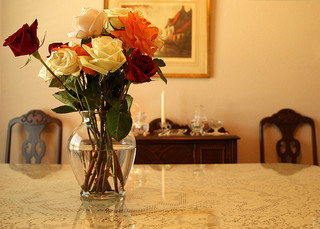

In [ ]:
data_dir = pathlib.Path(data_dir)
roses = list(data_dir.glob('roses/*'))
PIL.Image.open(str(roses[0]))

## <font color="#0b486b">III. Transfer learning with pretrained model</font> ##

We load the pretrained CNN model `VGG19`.

In [ ]:
# Load pretrained VGG19 model
model = models.vgg19(pretrained=True)
model = model.to(device)
summary(model, (3, 224, 224))

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:03<00:00, 180MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 224, 224]           1,792
              ReLU-2         [-1, 64, 224, 224]               0
            Conv2d-3         [-1, 64, 224, 224]          36,928
              ReLU-4         [-1, 64, 224, 224]               0
         MaxPool2d-5         [-1, 64, 112, 112]               0
            Conv2d-6        [-1, 128, 112, 112]          73,856
              ReLU-7        [-1, 128, 112, 112]               0
            Conv2d-8        [-1, 128, 112, 112]         147,584
              ReLU-9        [-1, 128, 112, 112]               0
        MaxPool2d-10          [-1, 128, 56, 56]               0
           Conv2d-11          [-1, 256, 56, 56]         295,168
             ReLU-12          [-1, 256, 56, 56]               0
           Conv2d-13          [-1, 256, 56, 56]         590,080
             ReLU-14          [-1, 256,

In [ ]:
print(model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

We freeze all model parameter, then we modify the last full connected layer (classification head) for 5 classes of our dataset.


In [ ]:
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

# Modify the last fully connected layer for our dataset
num_features = model.classifier[6].in_features
model.classifier[6] = nn.Linear(num_features, 5)
model = model.to(device)

Then, we build the BaseTrainer with Top-1 and Top-5 accuracy

In [ ]:
def top_k_accuracy(output, target, k=5):
    batch_size = target.size(0)
    _, pred = output.topk(k, 1, True, True)  # Get top-k predictions
    pred = pred.t()  # Transpose predictions for comparison
    correct = pred.eq(target.reshape(1, -1).expand_as(pred))  # Compare predictions with target
    correct_k = correct[:k].reshape(-1).float().sum(0, keepdim=True)  # Calculate correct top-k
    return correct_k.mul_(1.0 / batch_size).item()  # Calculate top-k accuracy

class BaseTrainer:
    def __init__(self, model, criterion, optimizer, train_loader, val_loader):
        self.model = model
        self.criterion = criterion
        self.optimizer = optimizer
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.stop_training = False

    def fit(self, num_epochs):
        self.num_batches = len(self.train_loader)
        for epoch in range(num_epochs):
            if self.stop_training:
                break
            print(f'Epoch {epoch + 1}/{num_epochs}')
            start_time = time.time()
            train_loss, train_accuracy = self.train_one_epoch()
            val_loss, top1_acc, top3_acc = self.validate_one_epoch()
            print(
                f' train_loss: {train_loss:.4f} - train_accuracy: {train_accuracy:.4f} - val_loss: {val_loss:.4f} - top1_acc: {top1_acc:.4f} - top3_acc: {top3_acc:.4f}'
            )
            self.on_epoch_end({'epoch': epoch, 'train_loss': train_loss, 'train_accuracy': train_accuracy, 'val_loss': val_loss, 'val_accuracy': top1_acc, 'top3_acc': top3_acc})

    def train_one_epoch(self):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0

        for i, data in enumerate(self.train_loader):
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)
            self.optimizer.zero_grad()
            outputs = self.model(inputs)
            loss = self.criterion(outputs, labels)
            loss.backward()
            self.optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_accuracy = correct / total
        train_loss = running_loss / self.num_batches
        return train_loss, train_accuracy

    def validate_one_epoch(self):
        self.model.eval()
        val_loss, correct, total_top1_acc, total_top3_acc, total = 0.0, 0, 0.0, 0.0, 0
        with torch.no_grad():
            for data in self.val_loader:
                inputs, labels = data
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                correct += (predicted == labels).sum().item()

                top1_acc = top_k_accuracy(outputs, labels, k=1)
                top3_acc = top_k_accuracy(outputs, labels, k=3)

                total_top1_acc += top1_acc * inputs.size(0)  # Custom evaluation metric
                total_top3_acc += top3_acc * inputs.size(0)  # Custom evaluation metric
                total += labels.size(0)

        val_loss /= len(self.val_loader)
        top1_acc = total_top1_acc / total
        top3_acc = total_top3_acc / total
        return val_loss, top1_acc, top3_acc

    def on_epoch_end(self, params):
        pass

We train the new model on the flower dataset. Note that at the moment, we only update the classifier on the top. Owning the existed patterns of `VGG19`, we can obtain a good performance.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9)
trainer = BaseTrainer(model, criterion, optimizer, train_loader, val_loader)
trainer.fit(num_epochs=5)

Epoch 1/5
 train_loss: 0.7090 - train_accuracy: 0.7272 - val_loss: 0.4249 - top1_acc: 0.8488 - top3_acc: 0.9837
Epoch 2/5
 train_loss: 0.4611 - train_accuracy: 0.8324 - val_loss: 0.3689 - top1_acc: 0.8706 - top3_acc: 0.9905
Epoch 3/5
 train_loss: 0.4086 - train_accuracy: 0.8535 - val_loss: 0.3391 - top1_acc: 0.8760 - top3_acc: 0.9905
Epoch 4/5
 train_loss: 0.3894 - train_accuracy: 0.8621 - val_loss: 0.3162 - top1_acc: 0.8924 - top3_acc: 0.9918
Epoch 5/5
 train_loss: 0.3648 - train_accuracy: 0.8665 - val_loss: 0.3111 - top1_acc: 0.8842 - top3_acc: 0.9918


We now train both the feature extractor and classifier with a small learning rate.

In [ ]:
# Unfreeze the last convolutional block
# for param in model.features[-7:].parameters():
#     param.requires_grad = True

# Unfreeze model parameter
for param in model.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-4, momentum=0.9)
trainer = BaseTrainer(model, criterion, optimizer, train_loader, val_loader)
trainer.fit(num_epochs=10)

Epoch 1/10
 train_loss: 0.3030 - train_accuracy: 0.8937 - val_loss: 0.2436 - top1_acc: 0.9101 - top3_acc: 0.9959
Epoch 2/10
 train_loss: 0.2409 - train_accuracy: 0.9084 - val_loss: 0.2141 - top1_acc: 0.9251 - top3_acc: 0.9973
Epoch 3/10
 train_loss: 0.1942 - train_accuracy: 0.9292 - val_loss: 0.2009 - top1_acc: 0.9101 - top3_acc: 0.9986
Epoch 4/10
 train_loss: 0.1677 - train_accuracy: 0.9384 - val_loss: 0.1821 - top1_acc: 0.9319 - top3_acc: 1.0000
Epoch 5/10
 train_loss: 0.1362 - train_accuracy: 0.9513 - val_loss: 0.1794 - top1_acc: 0.9387 - top3_acc: 0.9986
Epoch 6/10
 train_loss: 0.1190 - train_accuracy: 0.9571 - val_loss: 0.1780 - top1_acc: 0.9332 - top3_acc: 0.9986
Epoch 7/10
 train_loss: 0.1052 - train_accuracy: 0.9619 - val_loss: 0.1778 - top1_acc: 0.9373 - top3_acc: 0.9986
Epoch 8/10
 train_loss: 0.0793 - train_accuracy: 0.9748 - val_loss: 0.1698 - top1_acc: 0.9401 - top3_acc: 0.9986
Epoch 9/10
 train_loss: 0.0659 - train_accuracy: 0.9779 - val_loss: 0.1716 - top1_acc: 0.9401 - 

**<font color="red">Exercise 1</font>**: Use another pretrained model for example `ResNet50` for transfer learning and report your result.


---
### <font color="#0b486b"> <div  style="text-align:center">**THE END**</div> </font>